# Neural Network Baseline — FER-2013

This notebook implements and evaluates a fully connected neural network baseline
for facial-expression classification.

The neural network itself is implemented from scratch using NumPy. Scikit-learn
is used only for evaluation metrics and visualization.

## Classes

- angry
- happy
- sad
- neutral

## Architecture

48×48 grayscale image  
→ Flatten (2304 features)  
→ Dense (2304 → 128)  
→ ReLU  
→ Dense (128 → 4)  
→ Softmax

## Training configuration

- Train/test split: 80/20
- Validation split: none
- Batch size: 64
- Epochs: 30
- Learning rate: 0.01
- Loss: categorical cross-entropy
- Optimizer: basic gradient descent
- Random seed: 42

The purpose of this model is to establish a simple, reproducible baseline before
moving to more advanced architectures such as convolutional neural networks.

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from capstone_data.image_loader import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    IMAGE_EXTENSIONS,
    load_arrays,
    split_dataset,
)

from capstone_nn.layers import (
    Flatten,
    Dense,
)

from capstone_nn.activations import ReLU

from capstone_nn.losses import (
    softmax,
)

from capstone_nn.model import Sequential

from capstone_nn.training import (
    train_epoch,
    evaluate,
)

## Imports

NumPy is used for all neural-network mathematics, including matrix
multiplication, activation calculations, backpropagation, and parameter updates.

Matplotlib and scikit-learn are used only for evaluation and visualization.
They do not perform model training.

The custom `capstone_nn` package contains the neural-network components built
from scratch:

- `Flatten` reshapes each 48×48 image into 2304 features.
- `Dense` implements fully connected layers.
- `ReLU` introduces nonlinearity.
- `Sequential` connects layers into a complete model.
- `train_epoch()` performs mini-batch training.
- `evaluate()` evaluates the trained model without modifying its parameters.

# 1. Load the Final Cleaned Dataset

The preprocessing pipeline has already handled image discovery, cleaning,
duplicate handling, and reconstruction of the dataset.

This notebook begins from the standardized `data/final` directory.

Before training, the dataset is checked again to verify:

- all expected classes are present,
- class counts are reasonable,
- only supported image files are included,
- the corrected angry dataset is reflected in the final data.

In [3]:
FINAL_PATH = Path(
    r"C:\Users\Sheehizzle\Code\Capstone\Capstone-DATA4381\data\final"
)

assert FINAL_PATH.exists()

dataset = []

for class_name in CLASS_NAMES:

    class_dir = FINAL_PATH / class_name

    assert class_dir.exists(), (
        f"Missing class directory: {class_dir}"
    )

    for path in class_dir.iterdir():

        if (
            path.is_file()
            and path.suffix.lower() in IMAGE_EXTENSIONS
        ):

            dataset.append(
                {
                    "path": path,
                    "label": CLASS_TO_INDEX[class_name],
                    "class_name": class_name,
                }
            )

print("Total records:", len(dataset))

Total records: 16817


## Class Distribution

Class counts are inspected before training because class imbalance can strongly
affect a classifier.

A model trained using ordinary cross-entropy receives more examples from larger
classes. As a result, overall accuracy alone may hide poor performance on
smaller classes.

This distribution will therefore be considered later when interpreting the
confusion matrix, balanced accuracy, recall, and F1 scores.

In [4]:
class_counts = Counter(
    item["class_name"]
    for item in dataset
)

for class_name in CLASS_NAMES:
    print(
        f"{class_name:8s}: "
        f"{class_counts[class_name]}"
    )

angry   : 3089
happy   : 6677
sad     : 1245
neutral : 5806


# 2. Convert Images to Numerical Arrays

Each image is loaded as a 48×48 grayscale NumPy array.

Pixel intensities are normalized from the original 0–255 range to approximately
0–1. Normalization keeps numerical magnitudes smaller and makes optimization
more stable.

Images are stored as `float32`, while class labels are stored as integers.

In [6]:
X, y = load_arrays(
    dataset
)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("X dtype:", X.dtype)
print("y dtype:", y.dtype)

print(
    "Pixel range:",
    X.min(),
    X.max(),
)

Loading images nerds:   0%|          | 0/16817 [00:00<?, ?it/s]

X shape: (16817, 48, 48)
y shape: (16817,)
X dtype: float32
y dtype: int64
Pixel range: 0.0 1.0


In [7]:
assert X.ndim == 3
assert X.shape[1:] == (48, 48)
assert len(X) == len(y)

assert X.min() >= 0.0
assert X.max() <= 1.0

print("Array validation passed.")

Array validation passed.


# 3. Train/Test Split

The dataset is split into:

- 80% training data
- 20% test data

The split is stratified by class so that the relative class distribution is
preserved as closely as possible in both sets.

The test set is not used for backpropagation or parameter updates. It remains
unseen during training and is used only for final evaluation.

In [8]:
(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
) = split_dataset(
    X,
    y,
    train_ratio=0.80,
    val_ratio=0.0,
    test_ratio=0.20,
    seed=42,
)

print(
    "Train:",
    X_train.shape,
    y_train.shape,
)

print(
    "Test:",
    X_test.shape,
    y_test.shape,
)

assert (
    len(X_train)
    + len(X_test)
    == len(X)
)

print("80/20 split passed.")

Train: (13452, 48, 48) (13452,)
Test: (3365, 48, 48) (3365,)
80/20 split passed.


# 4. Neural Network Architecture

The baseline is a multilayer perceptron (MLP).

### Layer 1 — Flatten

Each 48×48 image contains:

48 × 48 = 2304 pixels

Flatten converts each image from shape `(48, 48)` to `(2304,)` without changing
the pixel values.

### Layer 2 — Dense: 2304 → 128

Each of the 128 hidden neurons receives all 2304 input features.

The layer computes:

Z₁ = XW₁ + b₁

Weights are initialized using He initialization because the following activation
function is ReLU.

### Layer 3 — ReLU

ReLU applies:

ReLU(x) = max(0, x)

This introduces nonlinearity into the network. Without a nonlinear activation,
multiple Dense layers would still collapse mathematically into a single linear
transformation.

### Layer 4 — Dense: 128 → 4

The final layer produces four logits, one for each expression class.

The logits are converted to probabilities using Softmax during training and
evaluation.

In [11]:
np.random.seed(42)

# IMPORTANT FOR REPRODUCIBILITY

model = Sequential(
    Flatten(),

    Dense(
        input_size=2304,
        output_size=128,
    ),

    ReLU(),

    Dense(
        input_size=128,
        output_size=4,
    ),
)

# 5. Training Configuration

Training uses mini-batch gradient descent.

A batch contains 64 images. For each batch:

1. The images pass forward through the network.
2. Softmax converts logits into class probabilities.
3. Cross-entropy measures prediction error.
4. Backpropagation computes gradients for every trainable parameter.
5. Gradient descent updates the weights and biases.

The parameter update is:

θ_new = θ_old − η∇L

where `η` is the learning rate.

Thirty epochs are used for the finalized baseline. One epoch means the model has
processed every training sample once.

The training data is reshuffled before each epoch.

In [12]:
EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 0.01
SEED = 42

rng = np.random.default_rng(
    SEED
)

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Epochs: 30
Batch size: 64
Learning rate: 0.01


# 6. Train the Baseline

Training loss measures how strongly the model disagrees with the correct labels.

Training accuracy measures the fraction of training predictions that are
correct.

During successful optimization, loss should generally decrease while accuracy
generally increases.

The exact values may fluctuate slightly between epochs because training occurs
using shuffled mini-batches.

In [13]:
train_history = []

for epoch in range(EPOCHS):

    metrics = train_epoch(
        model=model,
        X=X_train,
        y=y_train,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        rng=rng,
    )

    train_history.append(
        metrics
    )

    print(
        f"Epoch {epoch + 1:2d}/{EPOCHS} | "
        f"Loss: {metrics['loss']:.4f} | "
        f"Accuracy: {metrics['accuracy']:.4f}"
    )

Epoch  1/30 | Loss: 1.2179 | Accuracy: 0.4392
Epoch  2/30 | Loss: 1.1689 | Accuracy: 0.4857
Epoch  3/30 | Loss: 1.1391 | Accuracy: 0.5079
Epoch  4/30 | Loss: 1.1181 | Accuracy: 0.5251
Epoch  5/30 | Loss: 1.1080 | Accuracy: 0.5297
Epoch  6/30 | Loss: 1.0929 | Accuracy: 0.5384
Epoch  7/30 | Loss: 1.0896 | Accuracy: 0.5383
Epoch  8/30 | Loss: 1.0743 | Accuracy: 0.5502
Epoch  9/30 | Loss: 1.0643 | Accuracy: 0.5554
Epoch 10/30 | Loss: 1.0583 | Accuracy: 0.5574
Epoch 11/30 | Loss: 1.0486 | Accuracy: 0.5656
Epoch 12/30 | Loss: 1.0396 | Accuracy: 0.5697
Epoch 13/30 | Loss: 1.0393 | Accuracy: 0.5633
Epoch 14/30 | Loss: 1.0307 | Accuracy: 0.5709
Epoch 15/30 | Loss: 1.0198 | Accuracy: 0.5789
Epoch 16/30 | Loss: 1.0208 | Accuracy: 0.5743
Epoch 17/30 | Loss: 1.0117 | Accuracy: 0.5813
Epoch 18/30 | Loss: 1.0098 | Accuracy: 0.5823
Epoch 19/30 | Loss: 1.0011 | Accuracy: 0.5885
Epoch 20/30 | Loss: 1.0018 | Accuracy: 0.5862
Epoch 21/30 | Loss: 0.9928 | Accuracy: 0.5917
Epoch 22/30 | Loss: 0.9950 | Accur

## Training Curves

The following plots show how the model changes over the 30 training epochs.

A decreasing loss indicates that gradient descent is successfully minimizing the
training objective.

Increasing training accuracy indicates that the learned parameters are becoming
better at classifying the training examples.

These curves are also useful for identifying instability, stalled learning, or
possible overfitting.

In [15]:
epoch_numbers = np.arange(
    1,
    EPOCHS + 1,
)

train_losses = [
    item["loss"]
    for item in train_history
]

train_accuracies = [
    item["accuracy"]
    for item in train_history
]

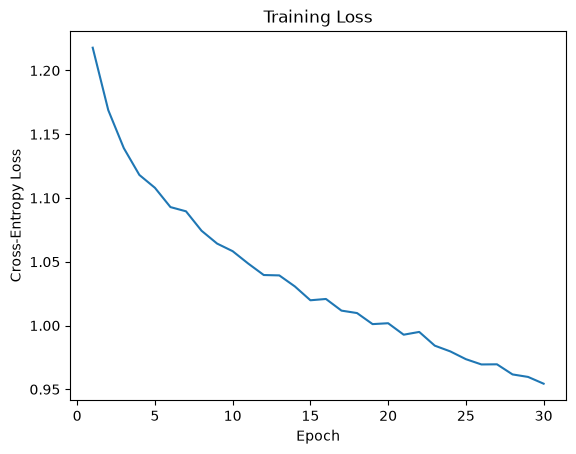

In [16]:
plt.figure()

plt.plot(
    epoch_numbers,
    train_losses,
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss")

plt.show()

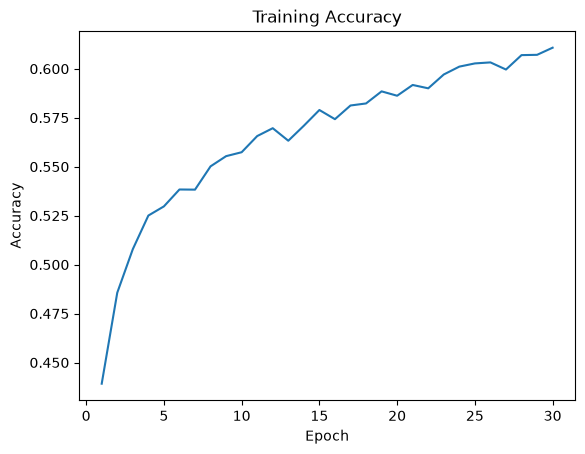

In [17]:
plt.figure()

plt.plot(
    epoch_numbers,
    train_accuracies,
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")

plt.show()

# 7. Test-Set Evaluation

After training is complete, the final parameters are evaluated on the untouched
test set.

No gradients are calculated and no parameters are updated during this stage.

The difference between training performance and test performance helps indicate
how well the learned representation generalizes to unseen images.

In [18]:
test_metrics = evaluate(
    model=model,
    X=X_test,
    y=y_test,
)

print(
    f"Test loss: "
    f"{test_metrics['loss']:.4f}"
)

print(
    f"Test accuracy: "
    f"{test_metrics['accuracy']:.4f}"
)

Test loss: 1.2615
Test accuracy: 0.4880


## Generate Test Predictions

The trained model produces four logits for every test image.

Softmax converts those logits into four class probabilities. The predicted class
is the index containing the largest probability.

In [19]:
test_logits = model.forward(
    X_test
)

test_probabilities = softmax(
    test_logits
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1,
)

assert (
    test_predictions.shape
    == y_test.shape
)

print(
    "Predictions generated:",
    len(test_predictions),
)

Predictions generated: 3365


# 8. Classification Metrics

Overall accuracy alone can be misleading when classes are imbalanced.

Therefore, the baseline is evaluated using several complementary metrics:

- **Accuracy:** fraction of all test samples classified correctly.
- **Balanced accuracy:** average recall across classes, giving each class equal
  importance.
- **Precision:** among samples predicted as a class, how many were correct.
- **Recall:** among samples actually belonging to a class, how many were found.
- **F1 score:** harmonic mean of precision and recall.
- **Support:** number of true test examples belonging to each class.

These metrics provide a much more complete picture than overall accuracy alone.

In [20]:
overall_accuracy = accuracy_score(
    y_test,
    test_predictions,
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_predictions,
)

print(
    f"Overall accuracy:  "
    f"{overall_accuracy:.4f}"
)

print(
    f"Balanced accuracy: "
    f"{balanced_accuracy:.4f}"
)

Overall accuracy:  0.4880
Balanced accuracy: 0.3338


In [21]:
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

       angry     0.5664    0.1036    0.1751       618
       happy     0.4626    0.9499    0.6222      1336
         sad     0.3571    0.0201    0.0380       249
     neutral     0.6141    0.2616    0.3669      1162

    accuracy                         0.4880      3365
   macro avg     0.5001    0.3338    0.3006      3365
weighted avg     0.5262    0.4880    0.4087      3365



### Interpreting the Classification Report

Recall is particularly important for this dataset because it shows whether the
network is effectively ignoring any expression class.

For example, a model can achieve respectable overall accuracy while rarely
predicting a minority class. Balanced accuracy and per-class recall make this
behavior visible.

Precision provides the complementary question: when the model predicts a
particular expression, how often is that prediction correct?

F1 score balances precision and recall into a single per-class measurement.

# 9. Confusion Matrix

The confusion matrix shows exactly where classification errors occur.

Rows correspond to the true expression.

Columns correspond to the model's predicted expression.

Values along the diagonal are correct predictions. Off-diagonal values show
which classes are being confused with one another.

This visualization is especially useful for identifying systematic errors that
are hidden by overall accuracy.

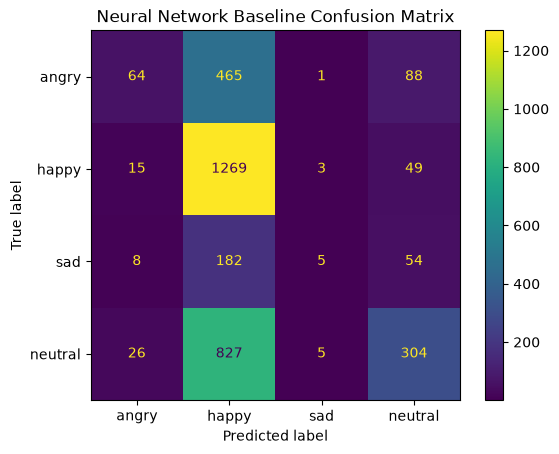

In [24]:
cm = confusion_matrix(
    y_test,
    test_predictions,
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

display.plot(
    values_format="d",
)

plt.title(
    "Neural Network Baseline Confusion Matrix"
)

plt.show()

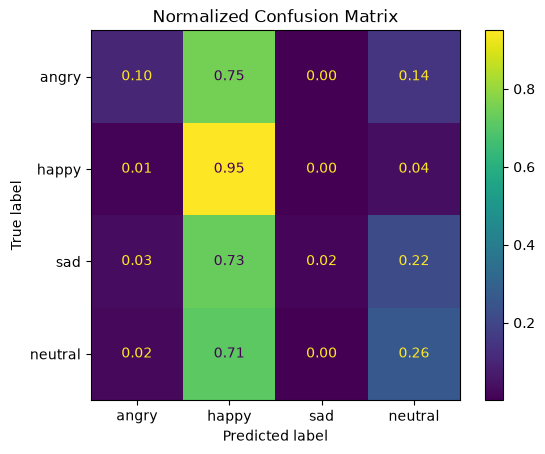

In [25]:
# Normalized version

cm_normalized = confusion_matrix(
    y_test,
    test_predictions,
    normalize="true",
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=CLASS_NAMES,
)

display.plot(
    values_format=".2f",
)

plt.title(
    "Normalized Confusion Matrix"
)

plt.show()

# 10. Prediction Distribution

The number of predictions assigned to each class is compared to the total test
set size.

This is useful for detecting class-collapse behavior. For example, if almost no
samples are predicted as `sad`, the model may be exploiting class imbalance
rather than learning a useful representation for that class.

In [26]:
print("Prediction distribution:")

for class_index, class_name in enumerate(
    CLASS_NAMES
):

    count = np.sum(
        test_predictions
        == class_index
    )

    fraction = (
        count
        / len(test_predictions)
    )

    print(
        f"{class_name:8s}: "
        f"{count:5d} "
        f"({fraction:.2%})"
    )

Prediction distribution:
angry   :   113 (3.36%)
happy   :  2743 (81.52%)
sad     :    14 (0.42%)
neutral :   495 (14.71%)


# 11. Baseline Summary

This experiment establishes the performance of a simple fully connected neural
network before introducing convolutional architectures or techniques intended
to address class imbalance.

Important observations should include:

1. Whether training loss consistently decreased over 30 epochs.
2. The gap between training and test performance.
3. The difference between ordinary and balanced accuracy.
4. Which classes achieve strong or weak recall.
5. Which expression pairs are most frequently confused.
6. Whether the model strongly favors particular classes.
7. Whether minority-class performance suggests the need for class weighting,
   sampling changes, augmentation, or a more appropriate architecture.

The purpose of the baseline is not necessarily to obtain the highest possible
accuracy. Its purpose is to establish a reproducible reference point against
which later improvements can be measured.

In [27]:
final_train = train_history[-1]

print("FINAL BASELINE RESULTS")
print("=" * 45)

print(
    f"Training samples:      {len(X_train)}"
)

print(
    f"Test samples:          {len(X_test)}"
)

print(
    f"Epochs:                {EPOCHS}"
)

print(
    f"Final training loss:   "
    f"{final_train['loss']:.4f}"
)

print(
    f"Final train accuracy:  "
    f"{final_train['accuracy']:.4f}"
)

print(
    f"Test loss:             "
    f"{test_metrics['loss']:.4f}"
)

print(
    f"Test accuracy:         "
    f"{overall_accuracy:.4f}"
)

print(
    f"Balanced accuracy:     "
    f"{balanced_accuracy:.4f}"
)

FINAL BASELINE RESULTS
Training samples:      13452
Test samples:          3365
Epochs:                30
Final training loss:   0.9544
Final train accuracy:  0.6108
Test loss:             1.2615
Test accuracy:         0.4880
Balanced accuracy:     0.3338
